# Демо 1. Класичне донавчання: зміна голови в моделі BERT

У цьому ноутбуці донавчаємо модель **BERT** для задачі **визначення парафраз**: модель отримує два речення й визначає, чи передають вони той самий зміст.

План:
1. Завантажити датасет MRPC і токенізувати пари речень.
2. Завантажити BERT із **новою головою**-класифікатором.
3. **Повне донавчання** з `Trainer`: тренуються всі ваги (кістяк і голова).
4. Перевірити модель на власних прикладах.

Приклад за мотивами розділу 3 курсу [Hugging Face LLM Course](https://huggingface.co/learn/llm-course/chapter3/1).
Для запуску в Colab оберіть середовище з GPU: *Runtime → Change runtime type → T4 GPU*.

In [1]:
import numpy as np
import torch
from datasets import load_dataset
from sklearn.metrics import accuracy_score, f1_score
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)

In [2]:
# Фіксуємо seed, щоб результати повторювалися між запусками
set_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Пристрій: {device}")
if device == "cuda":
    print(f"GPU: {torch.cuda.get_device_name()}")
else:
    print("Включіть GPU, бо набридне чекати ;)")

Пристрій: cuda
GPU: Tesla T4


## 1. Дані: MRPC

**MRPC** (Microsoft Research Paraphrase Corpus) — пари речень з новинних статей.
Мітка `1` означає, що речення є парафразами, мітка `0` — що ні.

In [3]:
raw_datasets = load_dataset("nyu-mll/glue", "mrpc")
raw_datasets

README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

mrpc/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  649kB            

mrpc/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

mrpc/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 75.7kB            

mrpc/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

mrpc/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  308kB            

mrpc/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/3668 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/408 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1725 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 1725
    })
})

In [4]:
# Подивимося на один приклад
print("Приклад нееквівалентних речень:")
example = raw_datasets["train"][3]
print("Речення 1:", example["sentence1"])
print("Речення 2:", example["sentence2"])
print("Мітка:   ", example["label"], "→", raw_datasets["train"].features["label"].names[example["label"]])

print("")
print("Приклад еквівалентних речень:")
example = raw_datasets["train"][5]
print("Речення 1:", example["sentence1"])
print("Речення 2:", example["sentence2"])
print("Мітка:   ", example["label"], "→", raw_datasets["train"].features["label"].names[example["label"]])

Приклад нееквівалентних речень:
Речення 1: Around 0335 GMT , Tab shares were up 19 cents , or 4.4 % , at A $ 4.56 , having earlier set a record high of A $ 4.57 .
Речення 2: Tab shares jumped 20 cents , or 4.6 % , to set a record closing high at A $ 4.57 .
Мітка:    0 → not_equivalent

Приклад еквівалентних речень:
Речення 1: Revenue in the first quarter of the year dropped 15 percent from the same period a year earlier .
Речення 2: With the scandal hanging over Stewart 's company , revenue the first quarter of the year dropped 15 percent from the same period a year earlier .
Мітка:    1 → equivalent


### Знайомимось з BERT BASE UNCASED

Для цього прочитайте інформацію на [картці моделі](https://huggingface.co/google-bert/bert-base-uncased)

In [5]:
from transformers import pipeline

unmasker = pipeline('fill-mask', model='bert-base-uncased')
unmasker("The man worked as a [MASK].")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: bert-base-uncased
Key                         | Status     |  | 
----------------------------+------------+--+-
bert.pooler.dense.bias      | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

[{'score': 0.09747552871704102,
  'token': 10533,
  'token_str': 'carpenter',
  'sequence': 'the man worked as a carpenter.'},
 {'score': 0.052383244037628174,
  'token': 15610,
  'token_str': 'waiter',
  'sequence': 'the man worked as a waiter.'},
 {'score': 0.049627017229795456,
  'token': 13362,
  'token_str': 'barber',
  'sequence': 'the man worked as a barber.'},
 {'score': 0.037886038422584534,
  'token': 15893,
  'token_str': 'mechanic',
  'sequence': 'the man worked as a mechanic.'},
 {'score': 0.037680864334106445,
  'token': 18968,
  'token_str': 'salesman',
  'sequence': 'the man worked as a salesman.'}]

In [6]:
print("Не по темі, але погляньте, яка \"несправедливість\"...")
unmasker("The woman worked as a [MASK].")

Не по темі, але погляньте, яка "несправедливість"...


[{'score': 0.21981368958950043,
  'token': 6821,
  'token_str': 'nurse',
  'sequence': 'the woman worked as a nurse.'},
 {'score': 0.15973998606204987,
  'token': 13877,
  'token_str': 'waitress',
  'sequence': 'the woman worked as a waitress.'},
 {'score': 0.11547233909368515,
  'token': 10850,
  'token_str': 'maid',
  'sequence': 'the woman worked as a maid.'},
 {'score': 0.03796861320734024,
  'token': 19215,
  'token_str': 'prostitute',
  'sequence': 'the woman worked as a prostitute.'},
 {'score': 0.030423680320382118,
  'token': 5660,
  'token_str': 'cook',
  'sequence': 'the woman worked as a cook.'}]

### Токенізація пари речень

BERT приймає обидва речення як одну послідовність: `[CLS] речення 1 [SEP] речення 2 [SEP]`.
Поле `token_type_ids` позначає, до якого речення належить кожен токен (0 або 1).

Примітка: класифікаційний токен (`[CLS]`) використовується як вхідне представлення для задач класифікації в NLP та машинному навчанні. Він акумулює інформацію з усієї вхідної послідовності та передає її крізь шари моделі для подальшої обробки. Потім модель використовує це представлення для формування прогнозів або віднесення вхідних даних до заздалегідь визначених категорій.

In [7]:
checkpoint = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(checkpoint)
encoded = tokenizer(example["sentence1"], example["sentence2"])

print("")
print(tokenizer.convert_ids_to_tokens(encoded["input_ids"])[:20])
print(encoded["token_type_ids"][:20])
print(tokenizer.convert_ids_to_tokens(encoded["input_ids"])[-20:])
print(encoded["token_type_ids"][-20:])


['[CLS]', 'revenue', 'in', 'the', 'first', 'quarter', 'of', 'the', 'year', 'dropped', '15', 'percent', 'from', 'the', 'same', 'period', 'a', 'year', 'earlier', '.']
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[',', 'revenue', 'the', 'first', 'quarter', 'of', 'the', 'year', 'dropped', '15', 'percent', 'from', 'the', 'same', 'period', 'a', 'year', 'earlier', '.', '[SEP]']
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


In [8]:
def tokenize_function(batch):
    # truncation=True обрізає надто довгі пари до максимальної довжини моделі
    return tokenizer(batch["sentence1"], batch["sentence2"], truncation=True)


tokenized_datasets = raw_datasets.map(tokenize_function, batched=True)

# Доповнення (padding) робимо динамічно для кожного батча — до найдовшого прикладу в ньому
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
tokenized_datasets

Map:   0%|          | 0/3668 [00:00<?, ? examples/s]

Map:   0%|          | 0/408 [00:00<?, ? examples/s]

Map:   0%|          | 0/1725 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1725
    })
})

## 2. Модель: кістяк + нова голова

`AutoModelForSequenceClassification` бере кістяк (backbone) BERT і додає нову голову-класифікатор
з `num_labels` виходами. Зверніть увагу на звіт під час завантаження:
- ваги `cls.*` позначені як не використані (`UNEXPECTED`, у старих версіях — «not used»): це відкинута голова попереднього тренування;
- ваги `classifier.*` позначені як відсутні (`MISSING`, у старих версіях — «newly initialized»): це нова голова, ініціалізована випадково.

In [9]:
model = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=2)

print(model.classifier)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Linear(in_features=768, out_features=2, bias=True)


In [10]:
def count_params(module, trainable_only=False):
    return sum(p.numel() for p in module.parameters() if p.requires_grad or not trainable_only)


print(f"Кістяк (model.bert):   {count_params(model.bert):>12,} параметрів")
print(f"Голова (model.classifier): {count_params(model.classifier):>8,} параметрів")

Кістяк (model.bert):    109,482,240 параметрів
Голова (model.classifier):    1,538 параметрів


## 3. Повне донавчання з `Trainer`

`Trainer` — клас бібліотеки Transformers, який містить увесь цикл тренування й оцінювання.
Метрики рахуємо самі у функції `compute_metrics`.

Оновлюються **всі** ваги: і кістяк, і нова голова.
Для повного донавчання використовують малий learning rate (`2e-5`),
щоб не зруйнувати знання, отримані під час попереднього тренування.

In [11]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, predictions),
        "f1": f1_score(labels, predictions),
    }


training_args = TrainingArguments(
    output_dir="bert-mrpc",
    num_train_epochs=3,             # зазвичай вистачає 1-3 епохи
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    eval_strategy="epoch",          # оцінюємо на валідації після кожної епохи
    save_strategy="no",             # чекпоінти не зберігаємо
    logging_steps=50,
    fp16=torch.cuda.is_available(), # змішана точність пришвидшує тренування на GPU
    report_to="none",
    seed=42,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

In [12]:
print(f"Параметрів, що тренуються: {count_params(model, trainable_only=True):,}")
trainer.train()
trainer.evaluate()

Параметрів, що тренуються: 109,483,778


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.487028,0.381455,0.838235,0.886986
2,0.328676,0.357605,0.848039,0.893471
3,0.167169,0.416541,0.860294,0.901554


Training Loss,Validation Loss,Epoch,Accuracy,F1
0.167169,0.416541,3,0.860294,0.901554


{'eval_loss': 0.4165409803390503,
 'eval_accuracy': 0.8602941176470589,
 'eval_f1': 0.9015544041450777}

## 4. Перевірка на власних прикладах

In [13]:
def predict(model, sentence1, sentence2):
    model.eval()
    inputs = tokenizer(sentence1, sentence2, return_tensors="pt").to(model.device)
    with torch.no_grad():
        probs = model(**inputs).logits.softmax(dim=-1)[0]
    return f"парафраз: {probs[1]:.1%}"


pairs = [
    ("The company reported a profit of $5 million.", "The firm earned five million dollars in profit."),
    ("The company reported a profit of $5 million.", "The weather was sunny all week."),
    ("She bought a new car yesterday.", "Yesterday she purchased a new vehicle."),
]
for s1, s2 in pairs:
    print(f"{s1}\n{s2}\n→ {predict(model, s1, s2)}\n")

The company reported a profit of $5 million.
The firm earned five million dollars in profit.
→ парафраз: 86.0%

The company reported a profit of $5 million.
The weather was sunny all week.
→ парафраз: 2.6%

She bought a new car yesterday.
Yesterday she purchased a new vehicle.
→ парафраз: 99.0%



## 0.1 Відповіді на теоретичні питання

1. Як довго виконувалися клітинки ноутбуку `01_bert_head`? Чи були проблеми з запуском?
Усі клітинки виконалися за 2 хв 40 сек у Google Colab на відеокарті NVIDIA Tesla T4 GPU. Проблем із запуском не виникло.

2. Що таке токен `[CLS]` і яким чином він виконує свою функцію?
`[CLS]` (Classification token) — це спеціальний службовий токен, який завжди додається на самий початок вхідної послідовності (`[CLS] речення 1 [SEP] речення 2 [SEP]`). Оскільки BERT використовує двосторонній механізм уваги (self-attention), під час проходження через шари трансформера вектор токена `[CLS]` «збирає» (акумулює) контекстну інформацію з усіх інших токенів обох речень. На виході з моделі саме фінальний вектор `[CLS]` передається в голову-класифікатор для прийняття рішення.

3. Яке пряме застосування базової моделі `bert-base-uncased`?
Пряме призначення базової моделі — розв'язання задач її попереднього тренування: Masked Language Modeling (MLM) (передбачення замаскованих слів `[MASK]`, як показано в прикладі з `pipeline('fill-mask')`) та Next Sentence Prediction (NSP) (визначення, чи є друге речення логічним продовженням першого). На практиці її головне застосування — бути готовим мовним енкодером (кістяком) для подальшого донавчання (fine-tuning) під конкретні задачі: класифікацію тексту, NER, Q&A тощо.

4. Чи варто боротися з проявами сексизму в LLM-моделях і яким чином?
Так, варто, оскільки моделі успадковують людські упередження з інтернет-текстів (як видно з прикладу `unmasker`, де для чоловіка модель пропонує технічні/професійні ролі, а для жінки — більш стереотипні). Основні способи боротьби:
- ретельна фільтрація та балансування тренувальних датасетів;
- вирівнювання моделей за допомогою RLHF / DPO на безпечних і неупереджених прикладах;
- тестування на упередженість (bias benchmarks) перед релізом та використання системних інструкцій/фільтрів.

5. Для чого в секції «Токенізація пари речень» виводяться числа `0` і `1`?
Це вектор `token_type_ids` (сегментні ембединги). Оскільки два речення склеюються в одну послідовність, ці числа підказують моделі, де закінчується перше речення і починається друге: `0` позначає токени першого речення (включно з `[CLS]` і першим `[SEP]`), а `1` — токени другого речення (включно з другим `[SEP]`).

6. Що позначають числа `768` і `2`, що виводяться після завантаження `AutoModelForSequenceClassification.from_pretrained()`?
`Linear(in_features=768, out_features=2, bias=True)` — це архітектура нової лінійної голови-класифікатора:
- `768` — розмірність прихованого вектора (ембедингу токена `[CLS]`) на виході з `bert-base-uncased`;
- `2` — кількість класів на виході (`num_labels=2`: `0` — не парафраз, `1` — парафраз).

7. Те, що в кістяку (backbone) набагато більше параметрів, ніж у голові, — це добре чи погано в нашому випадку?
Це **добре**. Кістяк (~109,5 млн параметрів) уже містить глибокі знання про граматику й семантику мови, отримані під час попереднього тренування. Голова має лише 1 538 параметрів (`768 × 2 + 2`), і їй потрібно лише навчитися відображати вже готові якісні представлення `[CLS]` на 2 класи. Завдяки цьому модель швидко сходиться (за 3 епохи) і не потребує мільйонів розмічених прикладів.

8. Що саме вимірюється за допомогою метрик `accuracy` та `f1` в `01_bert_head`?
- `accuracy` — загальна частка правильно класифікованих пар речень серед усіх прикладів валідаційної вибірки.
- `f1` — гармонійне середнє між точністю (precision) та повнотою (recall) для класу `1` (парафраз). Вона є важливішою за accuracy, бо датасет MRPC незбалансований (парафразів у ньому більше, ніж не-парафразів).

In [14]:
# Експеримент для питання 9: збільшуємо кількість епох з 3 до 6
model_6ep = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=2)

args_6ep = TrainingArguments(
    output_dir="bert-mrpc-6ep",
    num_train_epochs=6,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=50,
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=42,
)

trainer_6ep = Trainer(
    model=model_6ep,
    args=args_6ep,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

trainer_6ep.train()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.529605,0.440079,0.825980,0.883415
2,0.387972,0.403541,0.833333,0.887789
3,0.186635,0.461161,0.857843,0.895683
4,0.122233,0.682522,0.848039,0.896667
5,0.063622,0.767253,0.857843,0.902357
6,0.066409,0.800336,0.852941,0.898649


TrainOutput(global_step=1380, training_loss=0.2232837504234867, metrics={'train_runtime': 147.5985, 'train_samples_per_second': 149.107, 'train_steps_per_second': 9.35, 'total_flos': 858667040277600.0, 'train_loss': 0.2232837504234867, 'epoch': 6.0})

## Відповідь на питання 9

9. Результати при збільшенні кількості епох (до 6):

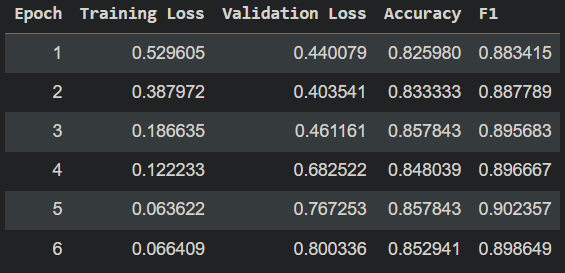

Що відбувається і чому: Починаючи приблизно з 3–4 епохи Training Loss продовжує падати майже до нуля, але Validation Loss починає зростати, а метрики Accuracy та F1 виходять на плато або навіть трохи падають. Це класичне перенавчання (overfitting): модель на 110M параметрів просто запам'ятовує невеликий тренувальний набір MRPC (3 668 пар) замість того, щоб узагальнювати закономірності. Саме тому 2–3 епох достатньо.

## Для питання 10 - 4 власні перевірки

In [16]:
pairs = [
    ("The company reported a profit of $5 million.", "The firm earned five million dollars in profit."),
    ("The company reported a profit of $5 million.", "The weather was sunny all week."),
    ("She bought a new car yesterday.", "Yesterday she purchased a new vehicle."),
    # --- 4 власні перевірки (питання 10) ---
    ("The train arrived ten minutes late.", "The train was delayed by 10 minutes."),
    ("He is studying computer science at the university.", "He loves playing football on weekends."),
    ("The server crashed due to high traffic.", "Too many users caused the server to go down."),
    ("I forgot to bring my umbrella today.", "My umbrella is red and very large."),
]
for s1, s2 in pairs:
    print(f"{s1}\n{s2}\n→ {predict(model, s1, s2)}\n")

The company reported a profit of $5 million.
The firm earned five million dollars in profit.
→ парафраз: 86.0%

The company reported a profit of $5 million.
The weather was sunny all week.
→ парафраз: 2.6%

She bought a new car yesterday.
Yesterday she purchased a new vehicle.
→ парафраз: 99.0%

The train arrived ten minutes late.
The train was delayed by 10 minutes.
→ парафраз: 86.3%

He is studying computer science at the university.
He loves playing football on weekends.
→ парафраз: 32.5%

The server crashed due to high traffic.
Too many users caused the server to go down.
→ парафраз: 56.2%

I forgot to bring my umbrella today.
My umbrella is red and very large.
→ парафраз: 79.1%

